# Lab 8 Edge Detection
**Student Name:** Faisal Abdullah Alshehri  
**Student ID:** 2240001737

## Objective
Apply and compare Sobel, Prewitt, and Canny edge detection using Python and OpenCV, then investigate how Canny thresholds affect the detected edges.

## Selected new image
I selected the supplied bird photograph, saved as **bird.png** (774 x 429 pixels). It is different from the images used in the original notebook. The scene includes a colourful bird with strong colour boundaries, fine feather detail, a textured branch, and a comparatively smooth blurred background.

**Run:** place `bird.png` beside this notebook and choose **Run All**. All results are already embedded below. If needed, install `opencv-python-headless`, `numpy`, and `matplotlib` first.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Put bird.png beside this notebook before choosing Run All.
image_path = Path('bird.png')
if not image_path.is_file():
    raise FileNotFoundError('Upload bird.png beside this notebook.')

img = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
if img is None:
    raise ValueError('OpenCV could not read bird.png.')
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
output_dir = Path('results')
output_dir.mkdir(exist_ok=True)

def to_uint8(response):
    # Scale before casting to prevent wraparound above 255.
    return cv2.normalize(
        response, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

print(f'Selected image: bird.png ({img.shape[1]} x {img.shape[0]})')

Selected image: bird.png (774 x 429)


## Task 1 Apply Edge Detection Methods

The original image and the three requested edge maps are displayed together below. Sobel and Prewitt use grayscale followed by a 5 x 5 Gaussian blur, as in the reference. Their x and y responses are combined as `sqrt(Gx**2 + Gy**2)` and normalized to 0-255 for display.

Sobel uses weighted smoothing within its derivative kernels, while Prewitt uses uniform weights. Canny uses the grayscale image with thresholds 100 and 200, following the reference example without an additional explicit Gaussian blur. It returns a binary edge map. These outputs illustrate each method; separately normalized gradient brightness is not an accuracy score.

In [2]:
# Sobel: first derivatives in x and y.
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel = to_uint8(cv2.magnitude(sobel_x, sobel_y))

# Prewitt: manually defined 3 x 3 derivative kernels.
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]],
                    dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]],
                    dtype=np.float64)
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt = to_uint8(cv2.magnitude(prewitt_x, prewitt_y))

# Canny: same grayscale input as the threshold experiment.
canny = cv2.Canny(gray, 100, 200)

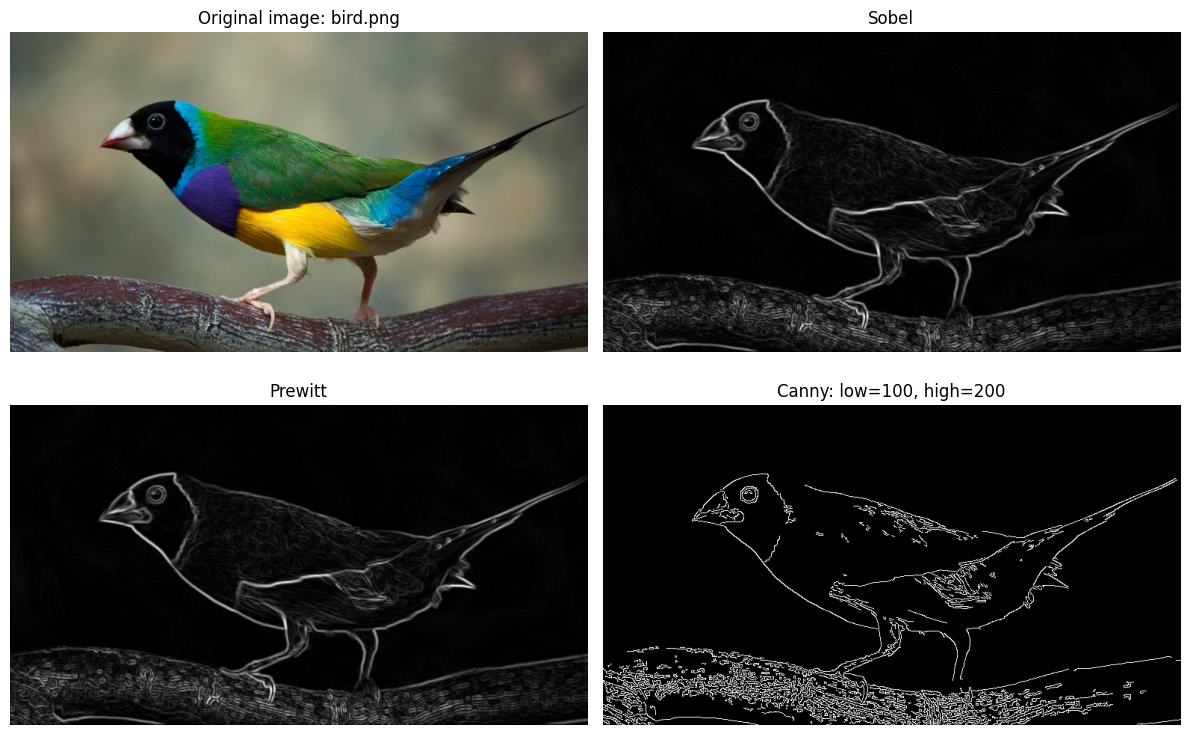

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.8))
panels = [rgb, sobel, prewitt, canny]
titles = ['Original image: bird.png', 'Sobel', 'Prewitt',
          'Canny: low=100, high=200']
for ax, panel, title in zip(axes.flat, panels, titles):
    ax.imshow(panel, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
fig.savefig(output_dir / 'task1_methods.png', dpi=160)
plt.show()
plt.close(fig)

### Task 1 Observations

Sobel and Prewitt produce similar gradient maps showing the bird outline, head and eye, tail, and the bark texture of the branch. Their responses have varying intensities and relatively broad boundaries. Canny produces thin binary edges and retains many high-contrast boundaries, while weaker changes are suppressed at thresholds 100 and 200. The smooth blurred background has almost no response, while the textured branch produces many.

## Task 2 Investigate the Effect of Canny Thresholds

Apply Canny using **(30, 90)**, **(50, 150)**, and **(100, 200)**, where each pair is `(low, high)`. The grayscale input and all other settings remain unchanged. Only the thresholds vary, so this experiment isolates their effect.

The high threshold identifies strong edge responses. Responses between the low and high thresholds are weak candidates and are kept only when connected through weak candidates to a strong edge. Responses below the low threshold are discarded.

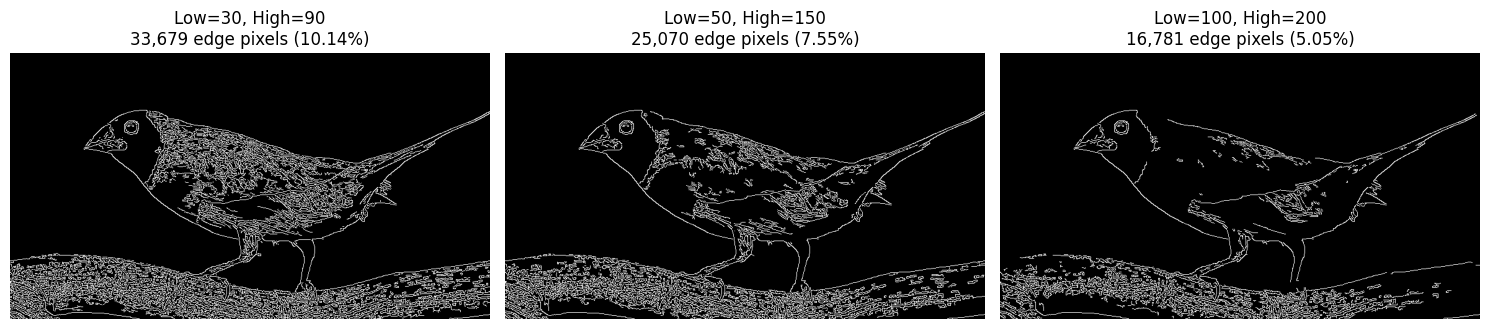

Low | High | Edge pixels | Percentage of image
 30 |   90 |      33,679 | 10.14%
 50 |  150 |      25,070 | 7.55%
100 |  200 |      16,781 | 5.05%


In [4]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]
canny_maps = {}
edge_counts = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

for ax, (low, high) in zip(axes, threshold_pairs):
    # Only the thresholds change; gray and defaults stay fixed.
    edges = cv2.Canny(gray, low, high)
    canny_maps[(low, high)] = edges
    count = int(np.count_nonzero(edges))
    percent = 100 * count / edges.size
    edge_counts.append((low, high, count, percent))
    ax.imshow(edges, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Low={low}, High={high}\n'
                 f'{count:,} edge pixels ({percent:.2f}%)')
    ax.axis('off')
    cv2.imwrite(str(output_dir / f'canny_{low}_{high}.png'), edges)

fig.tight_layout()
fig.savefig(output_dir / 'task2_canny_thresholds.png', dpi=180)
plt.show()
plt.close(fig)

print('Low | High | Edge pixels | Percentage of image')
for low, high, count, percent in edge_counts:
    print(f'{low:3d} | {high:4d} | {count:11,d} | {percent:.2f}%')